## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Aitor\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [3]:
import os

path =r"C:\Users\Aitor\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3"
os.listdir(path)

['amz_uk_price_prediction_dataset.csv']

In [4]:
df=pd.read_csv(r"C:\Users\Aitor\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3\\amz_uk_price_prediction_dataset.csv")

---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [7]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [40]:
best_sell=pd.crosstab(df["category"], df["isBestSeller"])
best_sell

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [44]:
best_sell_prop = pd.crosstab(df['category'],df['isBestSeller'],normalize='index')
best_sell_prop

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [45]:
best_sell_prop_sorted = (best_sell_prop[True].mul(100).round(2).sort_values(ascending=False))
best_sell_prop_sorted


category
Grocery                             5.81
Smart Home Security & Lighting      5.77
Health & Personal Care              5.77
Mobile Phone Accessories            4.25
Power & Hand Tools                  3.53
                                    ... 
CD, Disc & Tape Players             0.00
Snowboard Boots                     0.00
General Music-Making Accessories    0.00
Graphics Cards                      0.00
eBook Readers & Accessories         0.00
Name: True, Length: 296, dtype: float64

In [46]:
df_bs = best_sell_prop_sorted.to_frame(name="Best Seller (%)")
df_bs.head()

,Best Seller (%)
category,
Grocery,5.81
Smart Home Security & Lighting,5.77
Health & Personal Care,5.77
Mobile Phone Accessories,4.25
Power & Hand Tools,3.53


* The percentaje of Best Sellers per category is very low. Being the categories with most percentaje of Best Sellers under 6%
* The categories where being a best-seller is more prevalent are Grocery, Smart Home Security & Lighting, Health & Personal Care, Mobile Phone Accessories and Power & Hand Tools

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [47]:
from scipy.stats import chi2_contingency

In [48]:
best_sell

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [55]:
chi2, p_value, dof, expected = chi2_contingency(best_sell)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("There's an association between category and best-seller")
else:
    print("There's no evidence of association")


Chi-square statistic: 36540.2027
Degrees of freedom: 295
P-value: 0.000000
There's an association between category and best-seller


* The Chi-square test determines that the best-seller distribution is not independent of the product category

In [51]:
from scipy.stats.contingency import association
cramers_v = association(best_sell, method="cramer")
print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.1223


* A Chi-square test of independence showed that best-seller status is not independent of product category (p < 0.05).
* However, Cramér’s V indicates a weak association between category and best-seller status.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

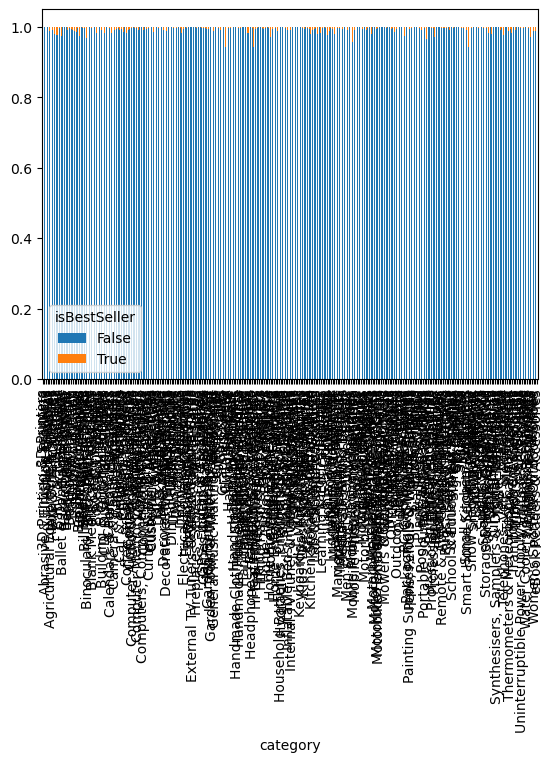

In [56]:
best_sell_prop.plot(kind='bar', stacked=True)
plt.show()

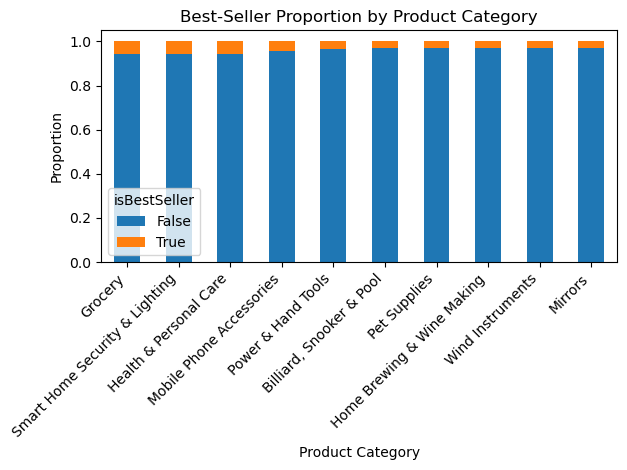

In [80]:
bs_sorted=best_sell_prop.sort_values(by=True, ascending=False)

bs_top=bs_sorted.head(10)
bs_top.plot(kind='bar', stacked=True)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Proportion")
plt.xlabel("Product Category")
plt.title("Best-Seller Proportion by Product Category")
plt.tight_layout()
plt.show()

* Because there are 296 categories, the full stacked-bar chart is hard to read
* We know that there are few categories that are relevant, we show only the top 10 categories where we can see the stacked values (in percentaje)

---

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*


In [81]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [88]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original dataset: {len(df)} rows")
print(f"Dataset without outliers: {len(df_no_outliers)} rows")
print(f"{len(df) - len(df_no_outliers)} results have being marked as outliers")

Original dataset: 2443651 rows
Dataset without outliers: 2115963 rows
327688 results have being marked as outliers


* We've created a new dataset without the outliers in the price column
* 327688 results of 2443651 have being marked as outliers

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [94]:
top_categories = df_no_outliers['category'].value_counts().head(20).index
top_categories

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object', name='category')

In [95]:
df_top_cat = df_no_outliers[df_no_outliers['category'].isin(top_categories)]

C:\Users\Aitor\AppData\Local\Temp\ipykernel_11372\1248355708.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_cat, x="category", y="price", palette="coolwarm")


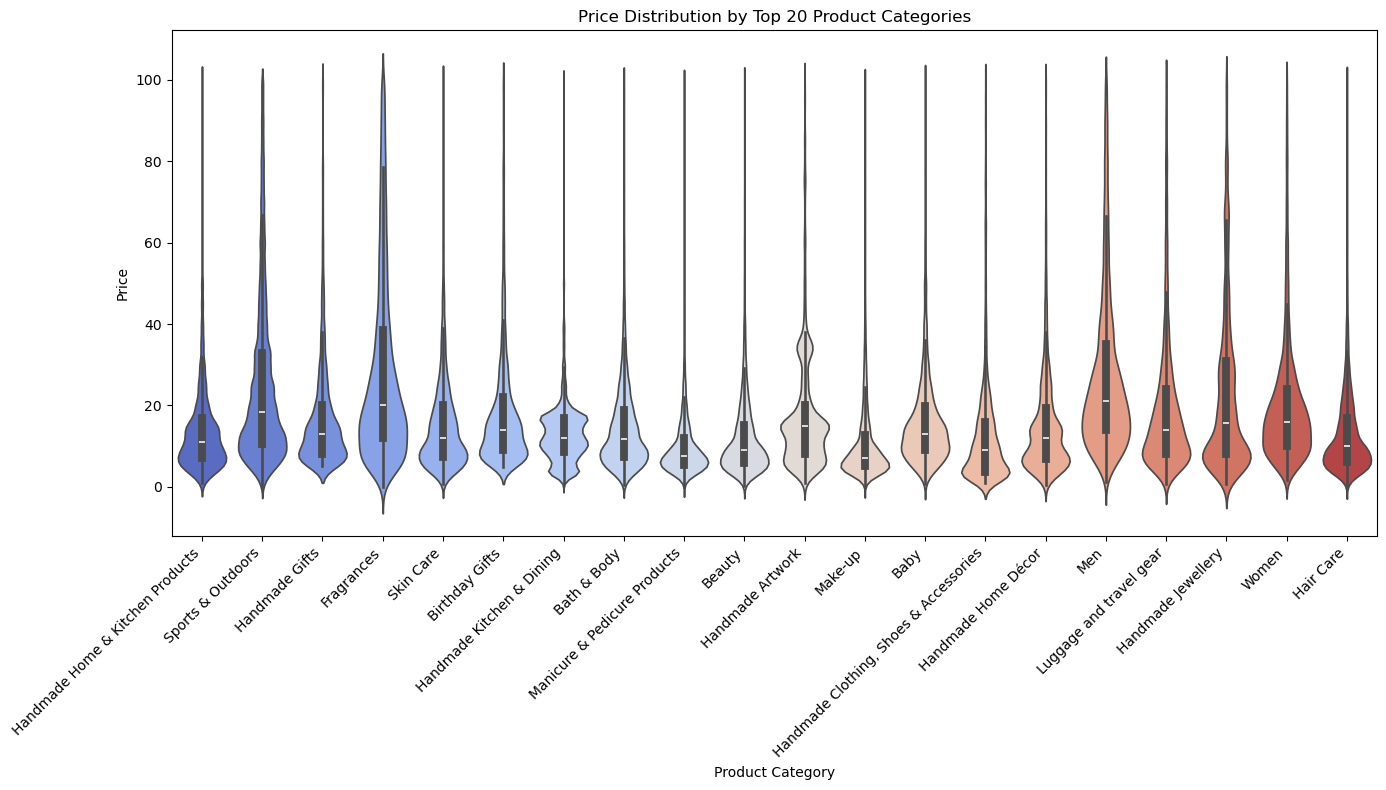

In [99]:
plt.figure(figsize=(14, 8))
sns.violinplot(data=df_top_cat, x="category", y="price", palette="coolwarm")
plt.xticks(rotation=45, ha='right')
plt.title("Price Distribution by Top 20 Product Categories")
plt.ylabel("Price")
plt.xlabel("Product Category")
plt.tight_layout()
plt.show()

* Every category in this top 20, displays a wide range of prices, with a thicker section below the median in most of them

In [102]:
median_prices_cat = df_no_outliers.groupby('category')['price'].median()
median_prices_cat_sorted = median_prices_cat.sort_values(ascending=False)

highest_median_category = median_prices_cat_sorted.index[0]
highest_median_value = median_prices_cat_sorted.iloc[0]

print(f"Category with highest median price: {highest_median_category}")
print(f"Median price: {highest_median_value:.2f}")

Category with highest median price: Desktop PCs
Median price: 74.00


* The product category that tends to have the highest median price is Desktop PCs.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

In [104]:
top10_categories = df_no_outliers['category'].value_counts().head(10).index
df_top10_cat = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]
avg_prices_top10= df_top10_cat.groupby('category')['price'].mean().sort_values(ascending=False)
avg_prices_top10

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

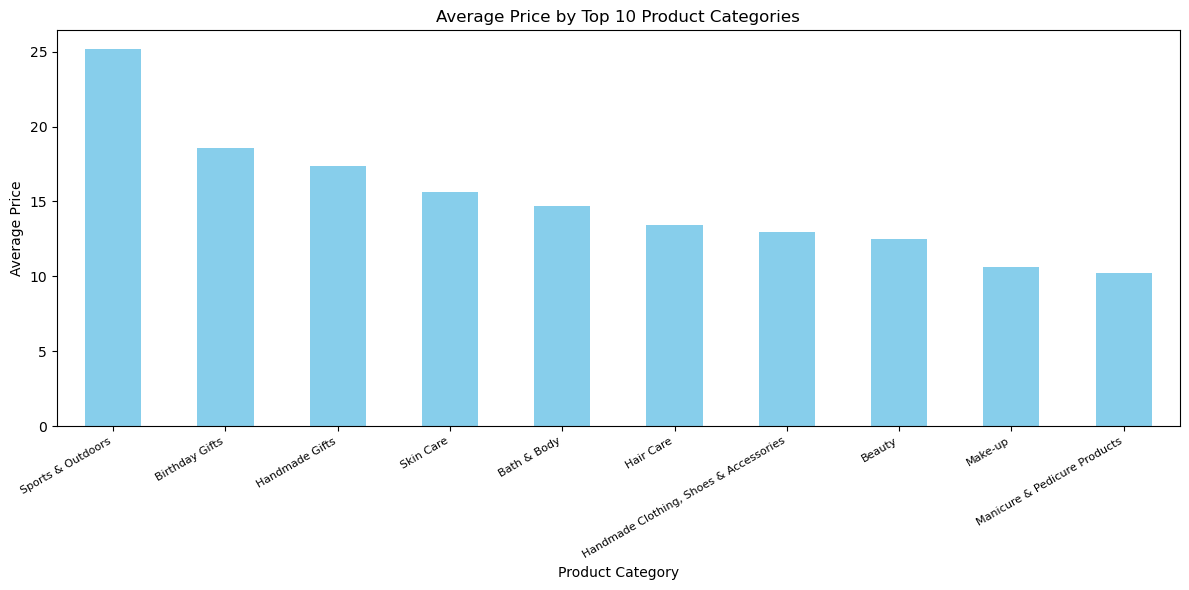

In [108]:
plt.figure(figsize=(12,6))
avg_prices_top10.plot(kind='bar', color='skyblue')
plt.title("Average Price by Top 10 Product Categories")
plt.ylabel("Average Price")
plt.xlabel("Product Category")
plt.xticks(rotation=30, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

In [109]:
avg_prices_sorted = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)

high_avg_cat = avg_prices_sorted.index[0]
high_avg_value = avg_prices_sorted.iloc[0]

print(f"Category with highest average price: {high_avg_cat}")
print(f"Average price: {high_avg_value:.2f}")

Category with highest average price: Motherboards
Average price: 68.77


* The  product category which commands the highest average price is Motherboards, which is not on the top 10 product categories (based on count)

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [118]:
df_no_out_no_zero_reviews = df_no_outliers[df_no_outliers['reviews'] != 0]
top_10_categories = df_no_out_no_zero_reviews['category'].value_counts().head(10).index
df_top10 = df_no_out_no_zero_reviews[df_no_out_no_zero_reviews['category'].isin(top_10_categories)]

* Because the data provided indicates that the products with no reviews are assigned a 0 stars rating, we firts remove those products without reviews

C:\Users\Aitor\AppData\Local\Temp\ipykernel_11372\2404050088.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category',y='stars', palette="coolwarm")


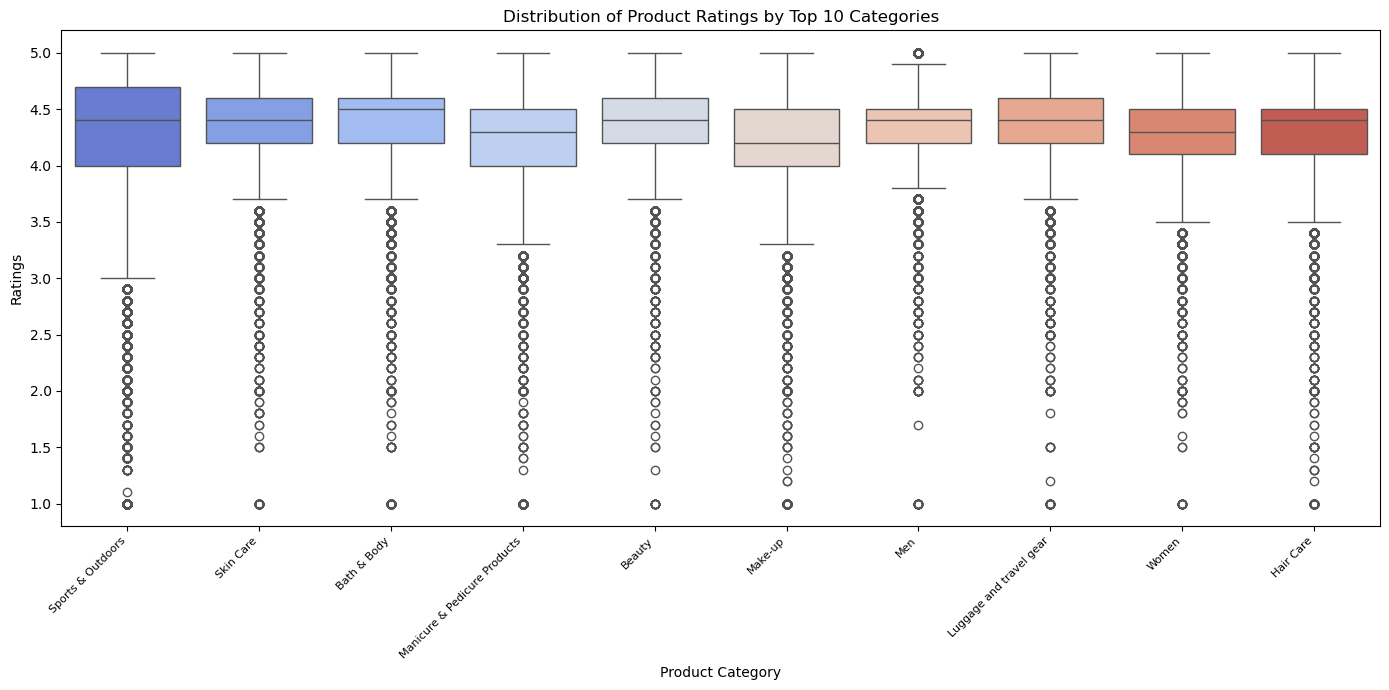

In [121]:
plt.figure(figsize=(14,7))
sns.boxplot(data=df_top10, x='category',y='stars', palette="coolwarm")

plt.xticks(rotation=45, ha='right', fontsize=8)
plt.title("Distribution of Product Ratings by Top 10 Categories")
plt.ylabel("Ratings")
plt.xlabel("Product Category")
plt.tight_layout()
plt.show()

* Most of the rating of the top 10 categories is between 4 and 5 stars, being the rest of reviews considered as outliers

In [122]:
median_ratings = df_no_out_no_zero_reviews.groupby('category')['stars'].median()
median_ratings_sorted = median_ratings.sort_values(ascending=False)

highest_median_rating_category = median_ratings_sorted.index[0]
highest_median_rating_value = median_ratings_sorted.iloc[0]

print(f"Category with highest median rating: {highest_median_rating_category}")
print(f"Median rating: {highest_median_rating_value:.2f}")

Category with highest median rating: Made in Italy Handmade
Median rating: 5.00


* Made in Italy Handmade is the perfect category as it has a median of 5 stars, the highest rating!

---

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

* Because the data provided indicates that the products with no reviews are assigned a 0 stars rating, we firts remove those products without reviews

In [137]:
df_no_zero_reviews = df[df['reviews'] != 0]
df_no_zero_reviews.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [138]:
corr_pearson = df_no_zero_reviews['price'].corr(df_no_zero_reviews['stars'], method='pearson')
corr_spearman = df_no_zero_reviews['price'].corr(df_no_zero_reviews['stars'], method='spearman')

print(f"Pearson correlation: {corr_pearson:.4f}")
print(f"Spearman correlation: {corr_spearman:.4f}")

Pearson correlation: -0.0049
Spearman correlation: 0.0200


* We calculate the correlation with the complete database (incluiding outliers) because the Spearman correlation it's robust to outliers
* As indicated before, we have removed products with zero reviews (which were were assigned a rating of zero stars) because they could introduce a bias into the analysis

* After removing products with no customer reviews and considering only items with valid ratings, the correlation between price and rating becomes negligible (Pearson and Spearman close to 0). This indicates that product price does not meaningfully influence customer ratings.

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot.

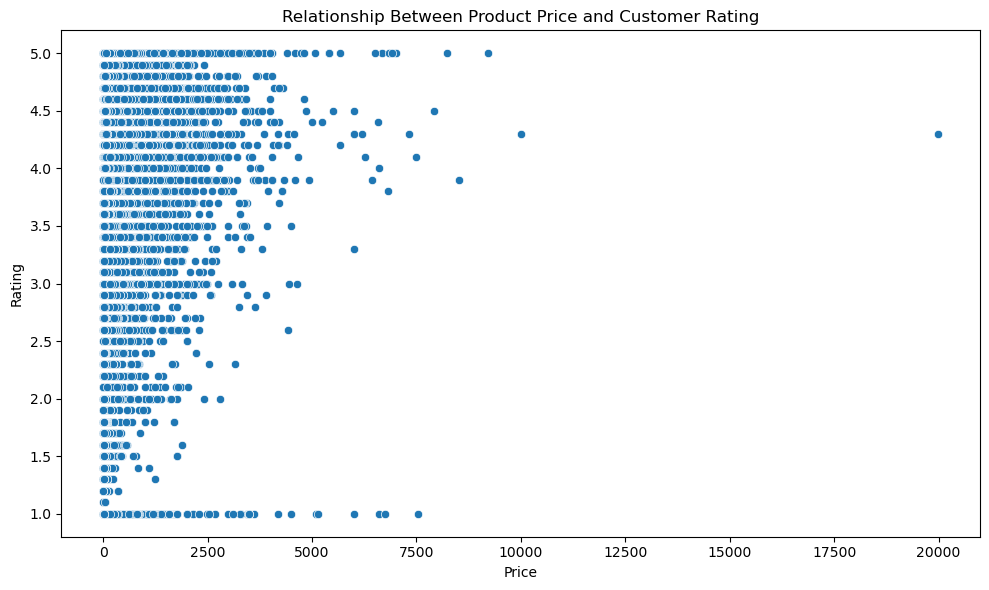

In [140]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_no_zero_reviews,x='price',y='stars')

plt.title("Relationship Between Product Price and Customer Rating")
plt.xlabel("Price")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

* The scatter plot shows a wide dispersion of customer ratings across all price levels, with no clear trend linking higher prices to better ratings. While most products are concentrated in lower price ranges, both high and low ratings are observed throughout the entire price spectrum. Overall, the visualization supports the correlation results, indicating that product price does not meaningfully influence customer ratings.

In [156]:
numeric_df = df_no_zero_reviews.select_dtypes(include='number')
numeric_df.columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

* We won't anlyse the "uid" column as it's only used for listing products in the database

In [157]:
columns_to_keep =['stars', 'reviews', 'price', 'boughtInLastMonth']
numeric_df_filtered = numeric_df[columns_to_keep]

In [158]:
corr_matrix = numeric_df_filtered.corr()
corr_matrix

,stars,reviews,price,boughtInLastMonth
stars,1.000000,0.033712,-0.004912,0.038359
reviews,0.033712,1.000000,-0.011032,0.096260
price,-0.004912,-0.011032,1.000000,-0.037266
boughtInLastMonth,0.038359,0.096260,-0.037266,1.000000


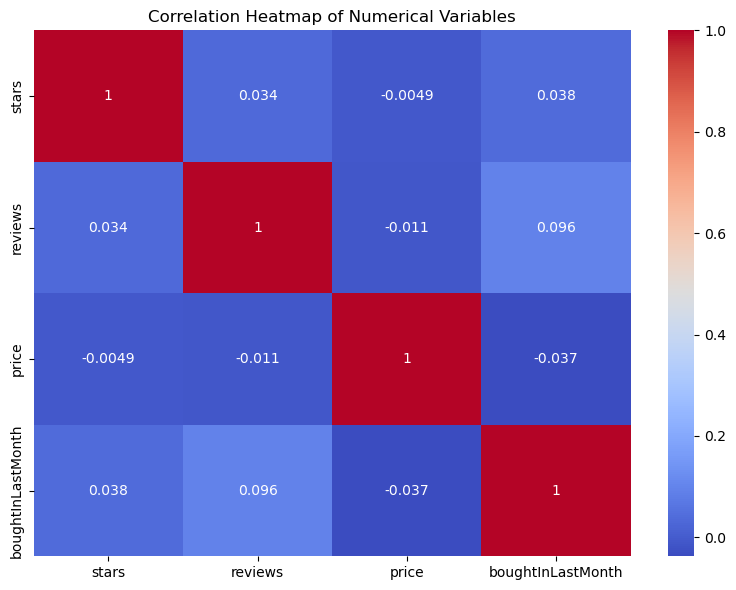

In [159]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm")

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

* The heatmap reveals uniformly weak correlations, highlighting the independence of price from customer ratings and purchasing behavior.
* The variable "boughtInLastMonth" shows weak positive correlations with both stars (0.11) and reviews (0.11), indicating that recently purchased products tend to have slightly higher ratings and review counts. However, these relationships remain weak.

<Figure size 800x600 with 0 Axes>

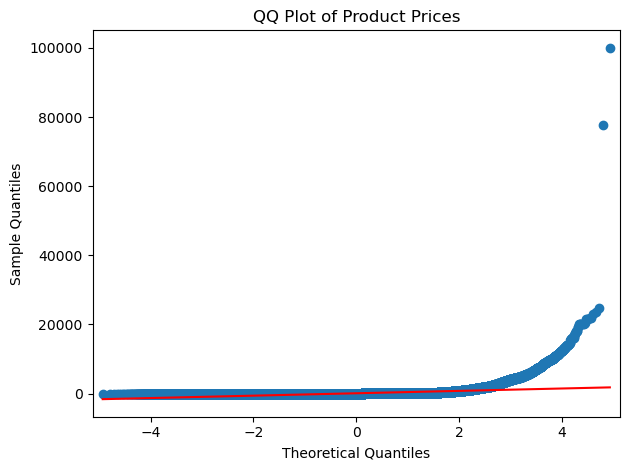

In [162]:
import statsmodels.api as sm

plt.figure(figsize=(8,6))
sm.qqplot(df['price'], line='s')

plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()

* The QQ plot indicates that product prices do not follow a normal distribution, as the points deviate strongly from the reference line, especially in the upper tail, showing a pronounced right skew and extreme values

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 